# 🗺️ Day 02 · Lines: rivers, roads and railways inside your region

**#30DayMapChallenge Uzbekistan 2026** · beginner tutorial, no experience needed

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NodiraTillayeva/30DayMapChallengeUzbekistan/blob/main/2026/Day%2002%20Lines/tutorial/day02_lines.ipynb)

In this notebook you will:
1. draw the **14 regions of Uzbekistan**,
2. turn them into **boundary lines**,
3. load thousands of **rivers and canals** from OpenStreetMap,
4. keep only the lines **inside your region** (this is called *clipping*),
5. make a cute map in your own style and **download it**.

**How to run a cell:** click inside the grey box and press **Shift + Enter** (or click the ▶ button on its left). Run the cells **from top to bottom**.

The first time, Colab may say *"Warning: This notebook was not authored by Google"*. Click **Run anyway**. It's safe.

## Step 0 · Get ready

This cell loads two tools:
- **geopandas** reads map data (it's like Excel, but every row also has a shape),
- **matplotlib** draws pictures.

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Where our data lives (in the project's GitHub folder)
BASE = "https://raw.githubusercontent.com/NodiraTillayeva/30DayMapChallengeUzbekistan/main/2026/Day%2002%20Lines/tutorial/data/"

print("Ready! ✅")

Ready! ✅


## Step 1 · Load the regions of Uzbekistan

A **boundary file** stores the outline of each region. We read it from the internet with one line.
The result is a table: one row per region, and a `geometry` column with its shape.

In [2]:
regions = gpd.read_file(BASE + "uzbekistan_regions.geojson")
regions

,region,geometry
0,Ferghana,"MULTIPOLYGON (((71.75498 39.94717, 71.75332 39..."
1,Tashkent Region,"POLYGON ((70.4457 41.02592, 70.40116 41.03998,..."
2,Namangan,"MULTIPOLYGON (((71.49908 40.75333, 71.41035 40..."
3,Andijon,"POLYGON ((72.21599 40.50135, 72.22234 40.53794..."
4,Sirdaryo,"MULTIPOLYGON (((68.70018 40.91634, 68.70814 40..."
5,Jizzakh,"POLYGON ((68.26419 40.62238, 68.25085 40.61168..."
6,Samarkand,"POLYGON ((66.62806 40.49066, 66.7541 40.48706,..."
7,Kashkadarya,"POLYGON ((65.68259 39.48338, 65.71581 39.49511..."
8,Surkhandarya,"POLYGON ((66.66625 37.98176, 66.6819 38.00613,..."
9,Karakalpakstan,"POLYGON ((62.13521 43.34774, 62.18533 43.31395..."


Now let's draw it. `cmap="Pastel1"` gives every region a soft colour.

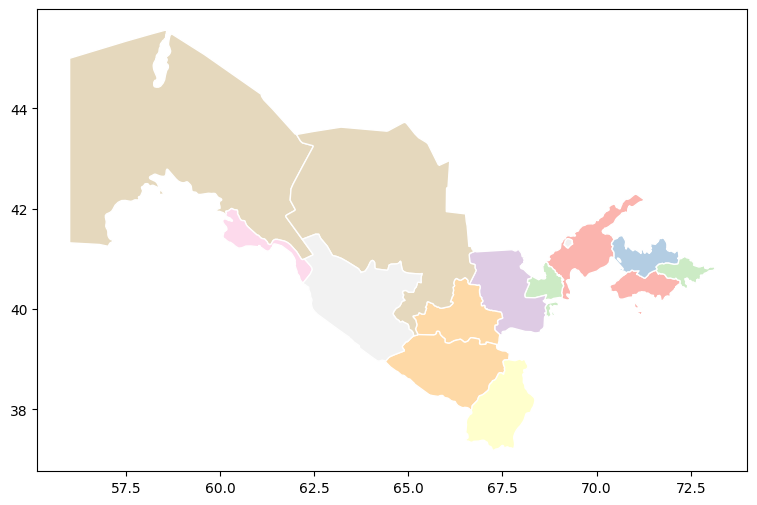

In [3]:
regions.plot(figsize=(10, 6), cmap="Pastel1", edgecolor="white")
plt.show()

## Step 2 · Boundaries are lines too!

Today's theme is **Lines**. A region is a *polygon* (a filled area), but its edge is a *line*.
`.boundary` keeps only the edges. Compare it with the map above.

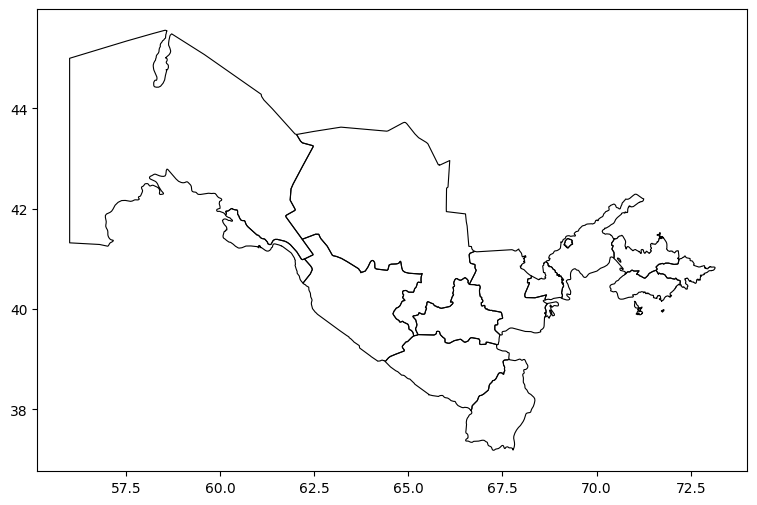

In [4]:
regions.boundary.plot(figsize=(10, 6), color="black", linewidth=0.8)
plt.show()

## Step 3 · Load rivers and canals

This file has about **34,000 waterways** from [OpenStreetMap](https://www.openstreetmap.org), the free map made by volunteers.
The column `kind` says what each line is: `river`, `canal`, `drain` (small irrigation ditch) or `stream` (mountain stream).

It's about 8 MB, so this cell takes a few seconds.

In [5]:
lines = gpd.read_file(BASE + "waterways.geojson")

print(len(lines), "lines")
lines["kind"].value_counts()

33793 lines


kind
stream    15051
canal      8368
drain      8234
river      2140
Name: count, dtype: int64

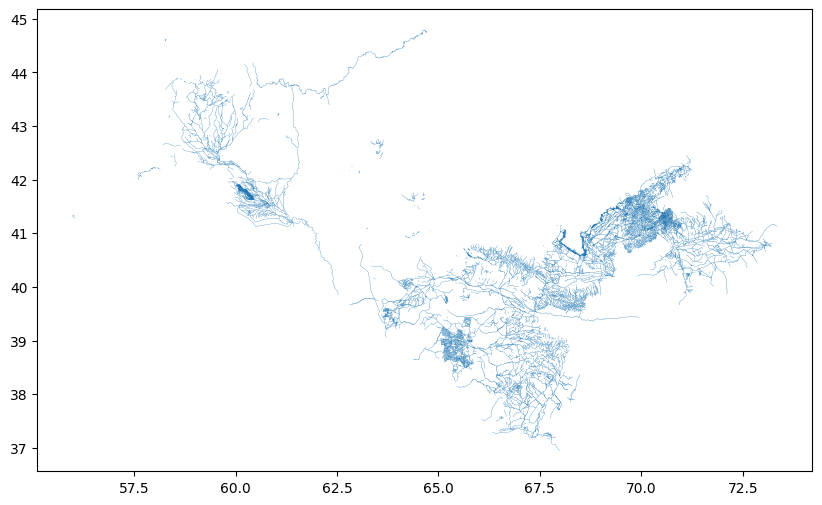

In [6]:
lines.plot(figsize=(10, 6), linewidth=0.2)
plt.show()

Look how many canals there are! Most of Uzbekistan's water goes through irrigation canals.

## Step 4 · Keep only the lines inside your region (clipping)

**Clipping** works like cookie cutting: the region is the cookie cutter, and we keep only the lines inside it.

👉 Change `MY_REGION` to any name from the table in Step 1 (for example `"Samarkand"` or `"Khorezm"`), then run the cell.

727 lines inside Ferghana


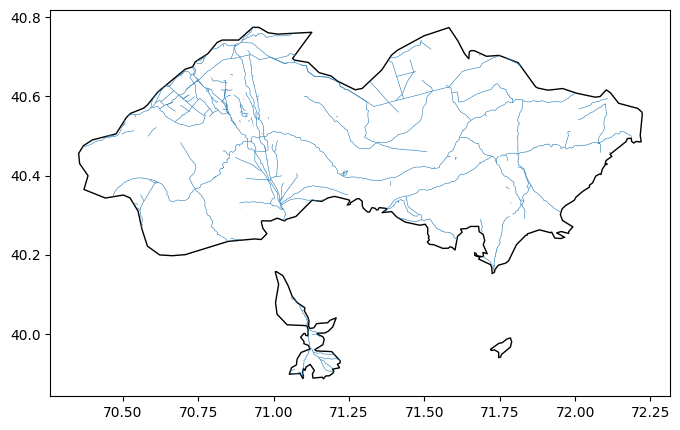

In [7]:
MY_REGION = "Ferghana"

area = regions[regions["region"] == MY_REGION]   # pick one row from the table
inside = gpd.clip(lines, area)                   # cut the lines with the region

print(len(inside), "lines inside", MY_REGION)

ax = area.boundary.plot(figsize=(8, 8), color="black", linewidth=1)
inside.plot(ax=ax, linewidth=0.4)
plt.show()

## Step 5 · Make it cute 🎨

Now the fun part. **Change the four settings below**, then run this cell and the next one.

| Setting | What you can write |
|---|---|
| `REGION` | a region name from Step 1, or `"Uzbekistan"` for the whole country |
| `LINES` | `"waterways"`, `"railways"` or `"roads"` |
| `PALETTE` | `"pastel"`, `"night"`, `"paper"` or `"mint"` |
| `TITLE` | any title you like |

Every combination gives a different map, so your map will be unique!

In [8]:
REGION  = "Ferghana"
LINES   = "waterways"
PALETTE = "pastel"
TITLE   = "Rivers and canals of Ferghana"

You don't need to change anything in the next cell. Just run it. (Curious? Read the `#` comments to see what each part does.)

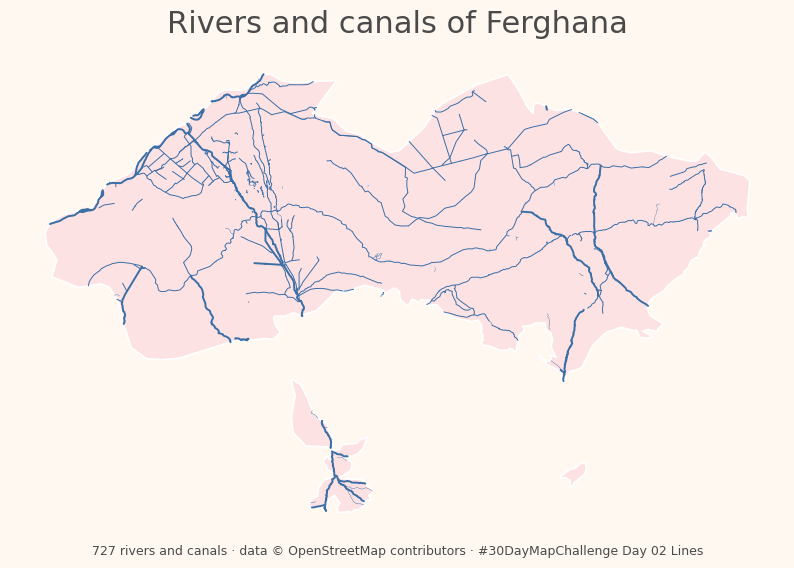

In [9]:
# Colours for each palette
PALETTES = {
    "pastel": dict(bg="#FFF8F0", fills=["#FDE2E4", "#E2ECE9", "#DFE7FD", "#FFF1E6", "#E9EDC9", "#F0E6EF", "#D7E3FC"],
                   edge="white", line="#3A6EA5", text="#4A4A4A"),
    "night":  dict(bg="#0E1726", fills=["#16233A"], edge="#2C3E5C", line="#7FD3FF", text="#E8EEF7", glow=True),
    "paper":  dict(bg="#F4EBDD", fills=["#EFE3CF"], edge="#A39482", line="#3B3B3B", text="#3B3B3B"),
    "mint":   dict(bg="#EFF8F4", fills=["#D8F0E6", "#CBEADB", "#E3F4EC"], edge="white", line="#1F7A5C", text="#2F4F44"),
}
# How thick each kind of line is (big rivers thick, small ditches thin)
WIDTHS = {"river": 1.4, "canal": 0.7, "drain": 0.25, "stream": 0.3,
          "motorway": 1.4, "trunk": 1.2, "primary": 0.7, "secondary": 0.3, "rail": 0.8}
NAMES = {"waterways": "rivers and canals", "railways": "railways", "roads": "main roads"}

colors = PALETTES[PALETTE]
data = gpd.read_file(BASE + LINES + ".geojson")
area = regions if REGION == "Uzbekistan" else regions[regions["region"] == REGION]
inside = gpd.clip(data, area)

fig, ax = plt.subplots(figsize=(10, 10), facecolor=colors["bg"])
ax.set_facecolor(colors["bg"])

# 1) regions as soft filled shapes, 2) their boundary lines on top
area.plot(ax=ax, color=[colors["fills"][i % len(colors["fills"])] for i in range(len(area))])
area.boundary.plot(ax=ax, color=colors["edge"], linewidth=1.2)

# 3) the lines, thick or thin depending on their kind (and thinner for big areas, so they don't blur together)
minx, miny, maxx, maxy = area.total_bounds
scale = min(1, (3 / max(maxx - minx, maxy - miny)) ** 0.5)
widths = inside["kind"].map(WIDTHS).fillna(0.3) * scale
if colors.get("glow"):   # a soft glow behind the lines
    inside.plot(ax=ax, color=colors["line"], linewidth=widths * 4, alpha=0.12)
inside.plot(ax=ax, color=colors["line"], linewidth=widths, capstyle="round")

ax.set_title(TITLE, fontsize=22, color=colors["text"], pad=14)
ax.text(0.5, -0.02, f"{len(inside):,} {NAMES[LINES]} · data © OpenStreetMap contributors · #30DayMapChallenge Day 02 Lines",
        transform=ax.transAxes, ha="center", va="top", fontsize=9, color=colors["text"])
ax.set_axis_off()
plt.show()

## Step 6 · Save and download your map

This saves the map as a picture and downloads it to your computer (look in your **Downloads** folder).

In [10]:
fig.savefig("my_day02_map.png", dpi=200, bbox_inches="tight", facecolor=fig.get_facecolor())

try:
    from google.colab import files
    files.download("my_day02_map.png")
except ImportError:
    print("Saved as my_day02_map.png")

Saved as my_day02_map.png


## 🎉 Done! What next?

- **Try more combinations:** go back to Step 5, change the settings and run the two cells again. Try `"night"` with `"roads"` for the whole country!
- **Share it:** make a folder named after your map's topic (e.g. `Canals of Khorezm`), put your picture and a short `README.md` with your name inside, and upload it to `2026/Day 02 Lines/` (see the main README of the project).
- Post it with **#30DayMapChallenge**.

**Data:** lines © [OpenStreetMap contributors](https://www.openstreetmap.org/copyright) (ODbL), via Geofabrik, simplified. Region boundaries: simplemaps.com.